# 📓 Média Aritmética e Ponderada

> **Meu Caderno Digital · Estatística e Probabilidade para IA e Dados**
> Módulo 01 · Estatística Descritiva › Medidas de Posição › Aula 01(Média Artmética e Ponderada).

### 🎯 Objetivo desta aula:

1. Explicar a média como **ponto de equilíbrio** e como o valor que **minimiza o erro quadrático**.
2. Escrever a média aritmética e a ponderada em notação formal (LaTeX) e **calculá-las na mão**.
3. Implementá-las **do zero** em Python e conferi-las contra NumPy e Pandas.
4. Decidir **quando usar a média simples e quando usar a ponderada**.
5. Reconhecer as armadilhas clássicas: outliers, média de médias, NaN com pesos, razões e o paradoxo de Simpson.
6. Mostrar onde a média aparece no trabalho de **Análise de Dados, Ciência de Dados, ML, DL e Engenharia**.

### 🗺️ Roteiro da aula

| Ato | Seções |
|---|---|
| **I · Por quê** | 1. O problema · 2. A intuição |
| **II · O quê** | 3. Definição formal · 4. Propriedades e relações |
| **III · Como** | 5. Na mão · 6. Em Python · 7. Visualizando |
| **IV · Cuidado** | 8. Armadilhas e limites |
| **V · Onde se aplica** | 9. No trabalho, por área · 10. Mini-caso |
| **VI · Fixar** | 11. Entrevista e exercícios · 12. Resumo e ponte |

> **Legenda dos blocos:** 🧠 Intuição · ⚠️ Armadilha · 🏭 No trabalho · 🎯 Entrevista

In [1]:
import math
import statistics

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

RNG_SEED = 42
rng = np.random.default_rng(RNG_SEED)

plt.rcParams.update({
    "figure.dpi": 100, "figure.figsize": (9, 4.2), "font.size": 11,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25,
})
COR = {"media": "#d1495b", "mediana": "#00798c", "ponderada": "#edae49", "base": "#30638e"}
pd.set_option("display.float_format", lambda v: f"{v:.4f}")

# O dataset fica em data/, dois níveis acima deste notebook
df = pd.read_csv("../../data/dataset_estatistica.csv")
print(f"Dataset carregado: {df.shape[0]} linhas x {df.shape[1]} colunas")

Dataset carregado: 200 linhas x 7 colunas


---
# ATO I · POR QUÊ
## 1 · O problema: qual é a nota da loja?

Você acaba de entrar como analista de dados em um e-commerce. Na primeira reunião, a diretoria pergunta:

> **"Qual é a nota de satisfação geral da nossa loja?"**

O dashboard atual já traz a nota média de cada categoria, junto com o número de avaliações que cada uma recebeu:

In [2]:
categorias = pd.DataFrame({
    "categoria":     ["Eletrônicos", "Roupas", "Livros"],
    "nota_media":    [4.8, 3.2, 4.5],
    "n_avaliacoes":  [10, 900, 90],
})
categorias

,categoria,nota_media,n_avaliacoes
0,Eletrônicos,4.8000,10
1,Roupas,3.2000,900
2,Livros,4.5000,90


In [3]:
media_das_medias = categorias["nota_media"].mean()
media_geral = np.average(categorias["nota_media"], weights=categorias["n_avaliacoes"])

print(f"Média das médias (simples)  : {media_das_medias:.2f}")
print(f"Média ponderada pelos n     : {media_geral:.2f}")
print(f"Diferença                   : {media_das_medias - media_geral:.2f} ponto(s)")

Média das médias (simples)  : 4.17
Média ponderada pelos n     : 3.33
Diferença                   : 0.83 ponto(s)


Dois números diferentes para **a mesma pergunta**. A média simples diz que a loja está ótima (4,17). A ponderada diz que ela é só razoável (3,33), porque quase todas as avaliações vêm de **Roupas**, a categoria mais mal avaliada.

Quem apresentar o 4,17 para a diretoria estará escondendo exatamente a categoria que mais importa. Isso levanta duas perguntas que vão guiar toda a aula:

1. **O que a média realmente faz** com os números?
2. **Quando cada observação merece o mesmo peso, e quando não merece?**

---
## 2 · A intuição: a média como ponto de equilíbrio

> 🧠 **Intuição 1 · A gangorra.** Imagine uma régua com pesos iguais colocados sobre os valores. A média é o ponto onde você apoia o dedo para a régua **não pender para nenhum lado**. Na física, é o *centro de massa*.

> 🧠 **Intuição 2 · A divisão igualitária.** Se você juntar tudo o que cada pessoa tem e redistribuir **igualmente**, cada uma fica com a média.

Veja a gangorra. À esquerda, todos os pesos iguais (média simples). À direita, o último valor **pesa 6 vezes mais**, então o ponto de equilíbrio é puxado para perto dele (média ponderada):

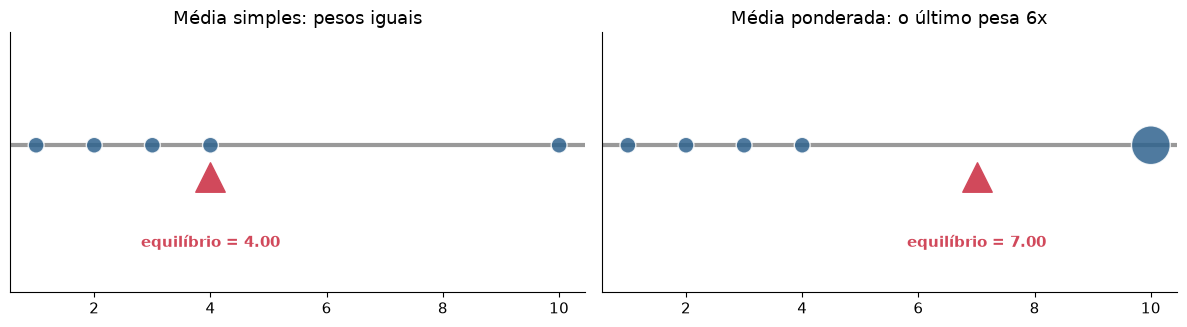

In [4]:
def gangorra(ax, x, w, titulo):
    x, w = np.asarray(x, float), np.asarray(w, float)
    m = np.average(x, weights=w)
    ax.axhline(0, color="#999999", lw=3, zorder=1)
    ax.scatter(x, np.zeros_like(x), s=130 * w, color=COR["base"], alpha=0.85,
               edgecolor="white", zorder=3)
    ax.scatter([m], [-0.14], marker="^", s=450, color=COR["media"], zorder=4)
    ax.annotate(f"equilíbrio = {m:.2f}", (m, -0.14), xytext=(m, -0.45),
                ha="center", color=COR["media"], fontweight="bold")
    ax.set_ylim(-0.65, 0.5); ax.set_yticks([]); ax.grid(False)
    ax.set_title(titulo)

x = [1, 2, 3, 4, 10]
fig, axs = plt.subplots(1, 2, figsize=(12, 3.4), sharex=True)
gangorra(axs[0], x, [1, 1, 1, 1, 1], "Média simples: pesos iguais")
gangorra(axs[1], x, [1, 1, 1, 1, 6], "Média ponderada: o último pesa 6x")
plt.tight_layout(); plt.show()

In [5]:
# A divisão igualitária: junte tudo e redistribua
patrimonio = np.array([100, 200, 600])
print(f"Total = {patrimonio.sum()}  ->  cada pessoa recebe {patrimonio.sum() / len(patrimonio):.0f}")
print(f"Média = {patrimonio.mean():.0f}")

Total = 900  ->  cada pessoa recebe 300
Média = 300


Guarde uma terceira ideia, que só vamos provar na seção 4 e que reaparece em regressão e redes neurais:

> 🧠 **Intuição 3 · O melhor "chute único".** Se você precisa prever um valor para *todo mundo* usando um único número, e o erro é medido ao **quadrado**, o melhor chute é a média. É por isso que a média é a base dos modelos de referência (*baselines*) e da função de perda MSE.

---
# ATO II · O QUÊ
## 3 · Definição formal

**Média aritmética (simples).** Para um conjunto de valores $x_1, x_2, \dots, x_n$:

$$\bar{x} = \frac{1}{n}\sum_{i=1}^{n} x_i$$

Quando falamos da **população** inteira (tamanho $N$), o parâmetro se chama $\mu$. Quando temos apenas uma **amostra**, calculamos $\bar{x}$ para **estimar** $\mu$:

| Símbolo | Nome | O que é |
|---|---|---|
| $\mu$ | média populacional | parâmetro fixo, em geral desconhecido |
| $\bar{x}$ | média amostral | estimativa calculada dos dados |
| $n$ | tamanho da amostra | quantidade de observações |

**Média ponderada.** Quando cada valor $x_i$ tem um peso $w_i \ge 0$:

$$\bar{x}_w = \frac{\sum_{i=1}^{n} w_i\, x_i}{\sum_{i=1}^{n} w_i} = \sum_{i=1}^{n} \tilde{w}_i\, x_i, \qquad \tilde{w}_i = \frac{w_i}{\sum_j w_j}$$

Os pesos normalizados $\tilde{w}_i$ somam 1. Por isso a ponderada é uma **combinação convexa** dos dados e **nunca sai do intervalo** $[\min x, \max x]$.

### Três conexões que valem ouro

1. **A simples é um caso particular da ponderada**, com todos os $w_i = 1$ (cada peso normalizado vale $1/n$).
2. **Dados agrupados em frequências** usam a ponderada: $\bar{x} = \dfrac{\sum f_i\, x_i}{n}$, em que $f_i$ é quantas vezes o valor $x_i$ aparece.
3. **Esperança matemática** (Módulo 02): $E[X] = \sum x\, p(x)$ é a média ponderada em que os pesos são **probabilidades**. Estamos olhando o mesmo objeto sob outro nome.

---
## 4 · Propriedades e relações

Em vez de apenas enunciar, vamos **verificar cada propriedade com código**.

### P1 · A soma dos desvios em torno da média é zero

$$\sum_{i=1}^{n}(x_i - \bar{x}) = 0$$

É a versão algébrica da gangorra: o que sobra de um lado compensa o que falta do outro.

In [6]:
pequeno = np.array([3.0, 7.0, 8.0, 12.0, 20.0])
print("média                 :", pequeno.mean())
print("desvios               :", pequeno - pequeno.mean())
print("soma dos desvios      :", (pequeno - pequeno.mean()).sum())

renda = df["renda_mensal"].dropna()
soma_desvios = (renda - renda.mean()).sum()
print(f"\nNa renda real ({len(renda)} valores): soma dos desvios = {soma_desvios:.2e}  (zero, a menos de erro de ponto flutuante)")
assert np.isclose(soma_desvios, 0, atol=1e-6)

média                 : 10.0
desvios               : [-7. -3. -2.  2. 10.]
soma dos desvios      : 0.0

Na renda real (189 valores): soma dos desvios = 7.28e-12  (zero, a menos de erro de ponto flutuante)


### P2 · A média minimiza o erro quadrático (a mediana, o erro absoluto)

Para qualquer número $c$ usado como "chute único":

$$\bar{x} = \arg\min_{c} \sum_{i=1}^{n}(x_i - c)^2 \qquad\qquad \text{mediana} = \arg\min_{c} \sum_{i=1}^{n}|x_i - c|$$

Vamos ver isso acontecer com um valor extremo no conjunto:

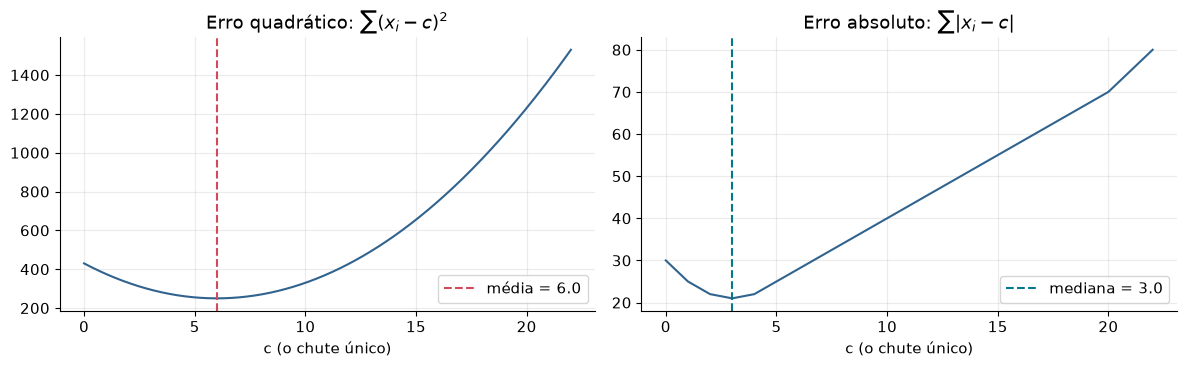

c que minimiza o erro quadrático (busca na grade): 6.00  | média = 6.00
c que minimiza o erro absoluto   (busca na grade): 3.00  | mediana = 3.00


In [7]:
x = np.array([1, 2, 3, 4, 20])
cs = np.linspace(0, 22, 441)
erro_quadratico = np.array([((x - c) ** 2).sum() for c in cs])
erro_absoluto   = np.array([np.abs(x - c).sum() for c in cs])

fig, axs = plt.subplots(1, 2, figsize=(12, 3.8))
axs[0].plot(cs, erro_quadratico, color=COR["base"])
axs[0].axvline(x.mean(), color=COR["media"], ls="--", label=f"média = {x.mean():.1f}")
axs[0].set_title(r"Erro quadrático: $\sum (x_i - c)^2$"); axs[0].set_xlabel("c (o chute único)"); axs[0].legend()

axs[1].plot(cs, erro_absoluto, color=COR["base"])
axs[1].axvline(np.median(x), color=COR["mediana"], ls="--", label=f"mediana = {np.median(x):.1f}")
axs[1].set_title(r"Erro absoluto: $\sum |x_i - c|$"); axs[1].set_xlabel("c (o chute único)"); axs[1].legend()
plt.tight_layout(); plt.show()

print(f"c que minimiza o erro quadrático (busca na grade): {cs[erro_quadratico.argmin()]:.2f}  | média = {x.mean():.2f}")
print(f"c que minimiza o erro absoluto   (busca na grade): {cs[erro_absoluto.argmin()]:.2f}  | mediana = {np.median(x):.2f}")

Repare na **forma** das curvas. O erro quadrático é uma parábola suave, e o valor extremo (20) *puxa* o mínimo para a direita. O erro absoluto é "pontudo" e quase não se importa com o 20. Essa é a raiz da diferença entre média e mediana, que vamos explorar na próxima aula.

### P3 · Linearidade

$$\overline{a x + b} = a\,\bar{x} + b \qquad\qquad \overline{x + y} = \bar{x} + \bar{y}$$

Mudar de unidade (R$ para US$, °C para °F) transforma a média **do mesmo jeito** que transforma cada valor:

In [8]:
cambio = 0.18   # fictício: 1 R$ = 0,18 US$
renda_usd = renda * cambio
assert np.isclose(renda_usd.mean(), cambio * renda.mean())
print(f"média em R$ = {renda.mean():.2f}  ->  média em US$ = {renda_usd.mean():.2f}  (= 0,18 x média em R$)")

celsius = np.array([18.0, 21.0, 25.0, 30.0])
fahrenheit = 9 / 5 * celsius + 32
assert np.isclose(fahrenheit.mean(), 9 / 5 * celsius.mean() + 32)
print(f"média em °C = {celsius.mean():.2f}  ->  média em °F = {fahrenheit.mean():.2f}  (= 9/5 x média + 32)")

média em R$ = 4901.09  ->  média em US$ = 882.20  (= 0,18 x média em R$)
média em °C = 23.50  ->  média em °F = 74.30  (= 9/5 x média + 32)


### P4 · A média geral é a média ponderada das médias dos grupos

Esta é a propriedade que resolve o mistério da seção 1. Se o grupo $g$ tem $n_g$ observações e média $\bar{x}_g$:

$$\bar{x} = \frac{\sum_g n_g\, \bar{x}_g}{\sum_g n_g}$$

Vamos confirmar com a renda real, agrupada por categoria:

In [9]:
por_cat = df.dropna(subset=["renda_mensal"]).groupby("categoria_frequente")["renda_mensal"].agg(["mean", "count"])
por_cat.columns = ["media_do_grupo", "n_do_grupo"]
display(por_cat)

media_geral_real      = renda.mean()
media_das_medias      = por_cat["media_do_grupo"].mean()
media_ponderada_grupo = np.average(por_cat["media_do_grupo"], weights=por_cat["n_do_grupo"])

print(f"\nMédia geral (todos os clientes)     : {media_geral_real:.4f}")
print(f"Média ponderada das médias (por n)  : {media_ponderada_grupo:.4f}   <- idêntica à geral")
print(f"Média simples das médias dos grupos : {media_das_medias:.4f}   <- diferente!")
assert np.isclose(media_geral_real, media_ponderada_grupo)

,media_do_grupo,n_do_grupo
categoria_frequente,,
Alimentos,4801.7086,22
Eletrônicos,5000.6868,57
Livros,4178.6490,30
Roupas,5128.3772,80



Média geral (todos os clientes)     : 4901.0920
Média ponderada das médias (por n)  : 4901.0920   <- idêntica à geral
Média simples das médias dos grupos : 4777.3554   <- diferente!


### P5 · Limites e fragilidade

- **Limitada pelos extremos:** $\min x \le \bar{x} \le \max x$ (e o mesmo vale para a ponderada).
- **Sem resistência a outliers:** um único valor pode levar a média a **qualquer lugar**. Dizemos que o *ponto de ruptura* (*breakdown point*) da média é 0%. A mediana aguenta até 50%.

In [10]:
base = np.array([10, 11, 12, 13, 14])
com_outlier = base.copy(); com_outlier[-1] = 14_000   # erro de digitação: 14 virou 14000

print(f"Sem outlier : média = {base.mean():>9.1f} | mediana = {np.median(base):.1f}")
print(f"Com outlier : média = {com_outlier.mean():>9.1f} | mediana = {np.median(com_outlier):.1f}")

Sem outlier : média =      12.0 | mediana = 12.0
Com outlier : média =    2809.2 | mediana = 12.0


### As médias formam uma família

A média aritmética é a mais conhecida, mas **não é a única**. Cada uma responde a um tipo de pergunta:

| Medida | Fórmula | Use quando | Aula |
|---|---|---|---|
| **Aritmética** | $\frac{1}{n}\sum x_i$ | valores somam de forma natural (notas, preços, rendas) | esta aula |
| **Ponderada** | $\frac{\sum w_i x_i}{\sum w_i}$ | observações têm importâncias ou tamanhos diferentes | esta aula |
| **Truncada** | média após cortar uma fração dos extremos | há outliers, mas você quer algo mais "eficiente" que a mediana | próxima |
| **Mediana** | valor central | distribuição assimétrica ou com outliers | próxima |
| **Geométrica** | $\sqrt[n]{\prod x_i}$ | taxas de crescimento e fatores multiplicativos | Aula futura |
| **Harmônica** | $\frac{n}{\sum 1/x_i}$ | razões e taxas (velocidade, preço por unidade, F1) | Aula futura |

Uma relação curiosa vale para valores positivos: **harmônica ≤ geométrica ≤ aritmética**.

In [11]:
fatores = [1.2, 0.8, 1.5, 2.0]
hm, gm, am = statistics.harmonic_mean(fatores), statistics.geometric_mean(fatores), statistics.fmean(fatores)
print(f"harmônica = {hm:.4f}  <=  geométrica = {gm:.4f}  <=  aritmética = {am:.4f}")
assert hm <= gm <= am

harmônica = 1.2308  <=  geométrica = 1.3027  <=  aritmética = 1.3750


---
# ATO III · COMO
## 5 · Na mão

Antes de usar qualquer biblioteca, vamos calcular com papel e lápis. É assim que você entende o que o código faz, e é assim que se pega erro de lógica depois.

**Exemplo.** Em uma disciplina, a nota final combina quatro avaliações:

| Avaliação | Nota $x_i$ | Peso $w_i$ |
|---|---|---|
| Prova 1 | 7 | 2 |
| Prova 2 | 8 | 3 |
| Trabalho | 6 | 1 |
| Projeto | 9 | 4 |

**Média simples** (ignora que o Projeto vale mais que o Trabalho):

$$\bar{x} = \frac{7 + 8 + 6 + 9}{4} = \frac{30}{4} = 7{,}5$$

**Média ponderada** (respeita os pesos):

$$\bar{x}_w = \frac{7\cdot 2 + 8\cdot 3 + 6\cdot 1 + 9\cdot 4}{2 + 3 + 1 + 4} = \frac{14 + 24 + 6 + 36}{10} = \frac{80}{10} = 8{,}0$$

A nota sobe de 7,5 para 8,0 porque os dois melhores resultados (8 e 9) são justamente os de maior peso.

Agora o mesmo cálculo em Python **puro**, com as validações que uma função séria precisa ter:

In [12]:
def media(x):
    """Média aritmética em Python puro."""
    if len(x) == 0:
        raise ValueError("a lista está vazia")
    total = 0.0
    for valor in x:
        total += valor
    return total / len(x)


def media_ponderada(x, w):
    """Média ponderada em Python puro, com validação dos pesos."""
    if len(x) != len(w):
        raise ValueError("x e w precisam ter o mesmo tamanho")
    if len(x) == 0:
        raise ValueError("a lista está vazia")
    if any(peso < 0 for peso in w):
        raise ValueError("pesos negativos não fazem sentido aqui")
    soma_pesos = sum(w)
    if soma_pesos == 0:
        raise ValueError("a soma dos pesos é zero")
    return sum(xi * wi for xi, wi in zip(x, w)) / soma_pesos


notas, pesos = [7, 8, 6, 9], [2, 3, 1, 4]
print("média simples   :", media(notas))
print("média ponderada :", media_ponderada(notas, pesos))

média simples   : 7.5
média ponderada : 8.0


In [13]:
# Testes: nossa implementação precisa concordar com NumPy
assert np.isclose(media(notas), np.mean(notas))
assert np.isclose(media_ponderada(notas, pesos), np.average(notas, weights=pesos))
assert np.isclose(media_ponderada(notas, [1, 1, 1, 1]), media(notas))   # pesos iguais = média simples

# E os casos de borda precisam falhar de forma clara
for chamada, descricao in [
    (lambda: media([]), "lista vazia"),
    (lambda: media_ponderada([1, 2], [1]), "tamanhos diferentes"),
    (lambda: media_ponderada([1, 2], [0, 0]), "soma dos pesos zero"),
    (lambda: media_ponderada([1, 2], [1, -1]), "peso negativo"),
]:
    try:
        chamada()
    except ValueError as erro:
        print(f"OK  {descricao:<22} -> ValueError: {erro}")

OK  lista vazia            -> ValueError: a lista está vazia
OK  tamanhos diferentes    -> ValueError: x e w precisam ter o mesmo tamanho
OK  soma dos pesos zero    -> ValueError: a soma dos pesos é zero
OK  peso negativo          -> ValueError: pesos negativos não fazem sentido aqui


### Bônus de engenharia: a média *incremental*

Em telemetria, logs e treinamento de modelos, os dados **chegam em fluxo** e você não guarda tudo na memória. É possível atualizar a média a cada novo valor, sem reler o passado:

$$\bar{x}_n = \bar{x}_{n-1} + \frac{x_n - \bar{x}_{n-1}}{n}$$

Guarde essa forma: trocando o $1/n$ por uma constante $\alpha$, ela vira a **média móvel exponencial** (EWMA), que você vai estudar na parte de séries temporais.

In [14]:
def media_incremental(fluxo):
    m, n = 0.0, 0
    for x in fluxo:
        n += 1
        m += (x - m) / n          # só guardamos m e n, nunca a lista inteira
    return m

leituras = rng.normal(loc=75, scale=5, size=10_000)   # ex.: temperatura de um sensor
print("média incremental :", round(media_incremental(leituras), 6))
print("média em lote     :", round(leituras.mean(), 6))
assert np.isclose(media_incremental(leituras), leituras.mean())

média incremental : 74.948751
média em lote     : 74.948751


---
## 6 · Em Python: NumPy, Pandas e `statistics`

Na prática ninguém reimplementa a média, mas é preciso saber **como cada ferramenta se comporta**, principalmente diante de `NaN`. Nosso dataset tem valores ausentes de propósito:

In [15]:
df.head()

,cliente_id,idade,categoria_frequente,renda_mensal,compras_ano,nota_satisfacao,peso_avaliacoes
0,1001,56,Eletrônicos,4238.3900,7,1.1000,22
1,1002,69,Roupas,2819.3700,8,3.0000,28
2,1003,46,Roupas,2675.7800,2,2.6000,7
3,1004,32,Roupas,3435.6300,5,2.8000,35
4,1005,60,Eletrônicos,3400.2600,4,5.0000,28


In [16]:
df.isna().sum()

cliente_id              0
idade                   0
categoria_frequente     0
renda_mensal           11
compras_ano             0
nota_satisfacao        16
peso_avaliacoes         0
dtype: int64

In [17]:
renda_col = df["renda_mensal"]           # 11 valores ausentes
arr = renda_col.to_numpy()

print(f"np.mean(Series do Pandas)      : {np.mean(renda_col):.2f}")
print(f"Series.mean()                  : {renda_col.mean():.2f}")
print(f"Series.mean(skipna=False)      : {renda_col.mean(skipna=False)}")
print(f"np.mean(array NumPy)           : {np.mean(arr)}")
print(f"np.nanmean(array NumPy)        : {np.nanmean(arr):.2f}")
print(f"statistics.fmean (sem NaN)     : {statistics.fmean(renda_col.dropna()):.2f}")

np.mean(Series do Pandas)      : 4901.09
Series.mean()                  : 4901.09
Series.mean(skipna=False)      : nan
np.mean(array NumPy)           : nan
np.nanmean(array NumPy)        : 4901.09
statistics.fmean (sem NaN)     : 4901.09


> ⚠️ **Armadilha.** O mesmo `np.mean` devolve um número com uma `Series` do Pandas (que ignora `NaN` por padrão) e devolve `nan` com um array NumPy. Se você trocar de tipo no meio do código, o resultado muda **sem aviso**. Decida conscientemente o que fazer com os ausentes.

### Média ponderada com `np.average`

`NumPy` não tem `np.weighted_mean`. A função é `np.average(..., weights=...)`. Ela **não** trata `NaN`: você precisa filtrar valor e peso **juntos**.

In [18]:
validos = df.dropna(subset=["nota_satisfacao", "peso_avaliacoes"])
print(f"Linhas totais: {len(df)} | com nota e peso válidos: {len(validos)}")

nota_simples = validos["nota_satisfacao"].mean()
nota_pond    = np.average(validos["nota_satisfacao"], weights=validos["peso_avaliacoes"])
print(f"\nNota média simples    : {nota_simples:.4f}")
print(f"Nota média ponderada  : {nota_pond:.4f}")

Linhas totais: 200 | com nota e peso válidos: 184

Nota média simples    : 2.9484
Nota média ponderada  : 2.9120


### Ponderada por grupo, de forma vetorizada

O `groupby` do Pandas calcula médias simples com facilidade, mas não tem média ponderada embutida. A solução elegante é somar $w \cdot x$ e $w$ por grupo e dividir. Vamos empacotar isso em uma função reutilizável (ela volta nos exercícios):

In [19]:
def media_ponderada_por_grupo(dados, valor, peso, grupo):
    """Média simples e ponderada de `valor` (com pesos `peso`) por `grupo`, ignorando linhas com NaN."""
    d = dados.dropna(subset=[valor, peso]).assign(_wx=lambda t: t[valor] * t[peso])
    g = d.groupby(grupo, observed=True).agg(
        n=(valor, "size"),
        soma_pesos=(peso, "sum"),
        soma_wx=("_wx", "sum"),
        simples=(valor, "mean"),
    )
    g["ponderada"] = g["soma_wx"] / g["soma_pesos"]
    g["diferenca"] = g["ponderada"] - g["simples"]
    return g[["n", "soma_pesos", "simples", "ponderada", "diferenca"]]


tabela = media_ponderada_por_grupo(df, "nota_satisfacao", "peso_avaliacoes", "categoria_frequente")
tabela

,n,soma_pesos,simples,ponderada,diferenca
categoria_frequente,,,,,
Alimentos,20,488,2.8850,2.6725,-0.2125
Eletrônicos,54,1221,3.1741,3.1426,-0.0315
Livros,31,759,2.5903,2.7515,0.1612
Roupas,79,2032,2.9506,2.8908,-0.0598


> 🧠 **Por que a diferença é modesta e sem padrão aqui?** Repare que a ponderada fica ora acima, ora abaixo da simples. Neste dataset sintético, o peso (`peso_avaliacoes`) foi sorteado **independentemente** da nota. Quando peso e valor não têm relação, ponderar muda pouco, e de forma aleatória. Na vida real eles costumam se relacionar (categorias mal avaliadas tendem a receber mais reclamações), e aí a diferença explode, exatamente como na seção 1. Vamos reproduzir isso no mini-caso da seção 10.

---
## 7 · Visualizando

Média é um número, e números escondem formas. Vamos **olhar** a distribuição da renda e posicionar a média e a mediana sobre ela:

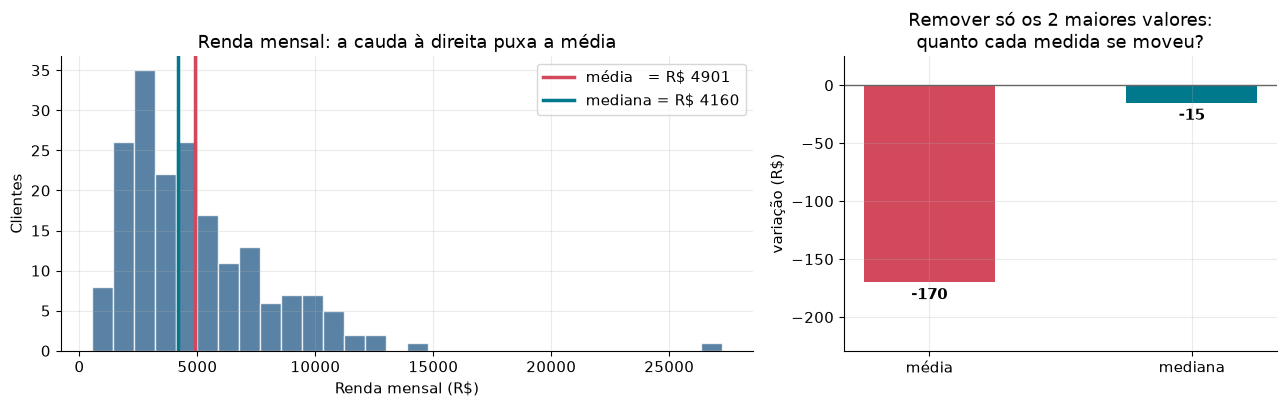

Média   : 4901.09 -> 4731.41   (variação de -169.68)
Mediana : 4160.30 -> 4145.35   (variação de -14.95)


In [20]:
renda = df["renda_mensal"].dropna()

fig, axs = plt.subplots(1, 2, figsize=(13, 4.2), gridspec_kw={"width_ratios": [1.6, 1]})

# (a) histograma com média e mediana
axs[0].hist(renda, bins=30, color=COR["base"], alpha=0.8, edgecolor="white")
axs[0].axvline(renda.mean(),   color=COR["media"],   lw=2.5, label=f"média   = R$ {renda.mean():.0f}")
axs[0].axvline(renda.median(), color=COR["mediana"], lw=2.5, label=f"mediana = R$ {renda.median():.0f}")
axs[0].set_title("Renda mensal: a cauda à direita puxa a média")
axs[0].set_xlabel("Renda mensal (R$)"); axs[0].set_ylabel("Clientes"); axs[0].legend()

# (b) quanto cada medida se move se removermos os 2 maiores valores?
sem_topo = renda.sort_values().iloc[:-2]
var_media   = sem_topo.mean()   - renda.mean()
var_mediana = sem_topo.median() - renda.median()
barras = axs[1].bar(["média", "mediana"], [var_media, var_mediana], color=[COR["media"], COR["mediana"]], width=0.5)
axs[1].axhline(0, color="#666666", lw=1)
axs[1].bar_label(barras, labels=[f"{var_media:+.0f}", f"{var_mediana:+.0f}"], padding=4, fontweight="bold")
axs[1].set_ylim(min(var_media, var_mediana) * 1.35, 25)
axs[1].set_ylabel("variação (R$)")
axs[1].set_title("Remover só os 2 maiores valores:\nquanto cada medida se moveu?")
plt.tight_layout(); plt.show()

print(f"Média   : {renda.mean():.2f} -> {sem_topo.mean():.2f}   (variação de {sem_topo.mean() - renda.mean():+.2f})")
print(f"Mediana : {renda.median():.2f} -> {sem_topo.median():.2f}   (variação de {sem_topo.median() - renda.median():+.2f})")

Em uma distribuição com **cauda longa à direita** (típica de renda, preços e tempos de espera), a média fica acima da mediana. Removendo só **dois** clientes em duzentos, a média se mexe visivelmente, e a mediana quase não.

Agora, simples versus ponderada lado a lado, por categoria:

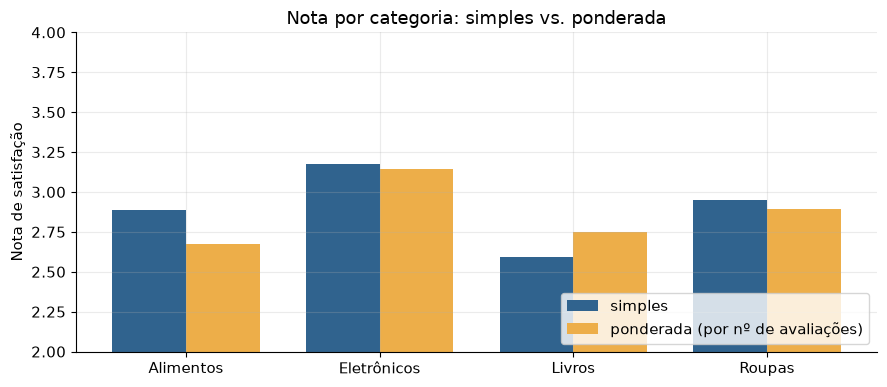

In [21]:
t = tabela.reset_index()
pos = np.arange(len(t)); larg = 0.38

fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(pos - larg/2, t["simples"],   larg, color=COR["base"],      label="simples")
ax.bar(pos + larg/2, t["ponderada"], larg, color=COR["ponderada"], label="ponderada (por nº de avaliações)")
ax.set_xticks(pos); ax.set_xticklabels(t["categoria_frequente"])
ax.set_ylim(2, 4); ax.set_ylabel("Nota de satisfação")
ax.set_title("Nota por categoria: simples vs. ponderada"); ax.legend(loc="lower right")
plt.tight_layout(); plt.show()

---
# ATO IV · CUIDADO
## 8 · Armadilhas e limites

A média parece inocente, e por isso é a medida mais mal usada da estatística. Sete armadilhas para nunca mais cair.

### 8.1 · Outliers

> ⚠️ Um único valor extremo move a média arbitrariamente (ponto de ruptura 0%). Mostramos isso na seção 4 (P5) e na seção 7. **Antes de reportar uma média, olhe o histograma.**

### 8.2 · Média de médias

> ⚠️ A média simples das médias dos grupos só coincide com a média geral se **todos os grupos tiverem o mesmo tamanho**. Era o erro do 4,17 da seção 1. A correção é ponderar pelos $n_g$ (propriedade P4).

### 8.3 · Valores ausentes e pesos desalinhados

In [22]:
d = df[["nota_satisfacao", "peso_avaliacoes"]]
certo = np.average(d.dropna()["nota_satisfacao"], weights=d.dropna()["peso_avaliacoes"])

# Erro 1: preencher NaN com 0 -> as notas ausentes viram "nota zero" e puxam tudo para baixo
errado_zero = np.average(d["nota_satisfacao"].fillna(0), weights=d["peso_avaliacoes"])

# Erro 2: descartar NaN só da nota e esquecer os pesos -> desalinhamento
try:
    np.average(d["nota_satisfacao"].dropna(), weights=d["peso_avaliacoes"])
except Exception as erro:
    msg_erro = f"{type(erro).__name__}: {erro}"

print(f"Correto (filtra nota E peso juntos) : {certo:.4f}")
print(f"Errado (fillna(0))                  : {errado_zero:.4f}   <- viés para baixo")
print(f"Errado (dropna só na nota)          : {msg_erro}")

Correto (filtra nota E peso juntos) : 2.9120
Errado (fillna(0))                  : 2.6759   <- viés para baixo
Errado (dropna só na nota)          : TypeError: Axis must be specified when shapes of a and weights differ.


> ⚠️ O Erro 2 pelo menos **avisa**. Pior seria um desalinhamento silencioso, quando os tamanhos coincidem por acaso mas as linhas não correspondem. Filtre sempre o `DataFrame` inteiro (`dropna(subset=[valor, peso])`) antes de separar as colunas.

### 8.4 · Pesos inválidos

In [23]:
# Soma dos pesos igual a zero: o NumPy se recusa
try:
    np.average([4, 5], weights=[0, 0])
except ZeroDivisionError as erro:
    print("pesos [0, 0]      ->", type(erro).__name__, "-", erro)

# Pesos negativos: o NumPy aceita calado e devolve um resultado sem sentido
resultado = np.average([4, 5, 1], weights=[1, -2, 2])
print(f"pesos [1, -2, 2]  -> {resultado}   (fora do intervalo [1, 5]!)")

pesos [0, 0]      -> ZeroDivisionError - Weights sum to zero, can't be normalized
pesos [1, -2, 2]  -> -4.0   (fora do intervalo [1, 5]!)


### 8.5 · Média de variável ordinal e média que esconde polarização

Notas de 1 a 5 estrelas são **ordinais**: a distância entre 1 e 2 não é necessariamente igual à distância entre 4 e 5. Tirar a média é uma convenção útil, mas esconde a forma da distribuição:

In [24]:
polarizado = np.array([1, 1, 1, 5, 5, 5])   # amam ou odeiam
consenso   = np.array([3, 3, 3, 3, 3, 3])   # todos mornos

for nome, notas_ in [("polarizado", polarizado), ("consenso", consenso)]:
    print(f"{nome:<11} média = {notas_.mean():.1f} | desvio padrão = {notas_.std(ddof=0):.2f}")

polarizado  média = 3.0 | desvio padrão = 2.00
consenso    média = 3.0 | desvio padrão = 0.00


Mesma média (3,0), públicos completamente diferentes. **Sempre acompanhe a média de uma medida de dispersão** (aula de Variância e Desvio Padrão) ou mostre a distribuição das notas.

### 8.6 · Média de razões: quando a aritmética erra

Você vai de casa ao trabalho a 60 km/h e volta a 40 km/h. Qual foi a velocidade média? Não é 50.

In [25]:
v_ida, v_volta = 60, 40
d_trecho = 120   # km, mesmo trecho nos dois sentidos

tempo_total = d_trecho / v_ida + d_trecho / v_volta
v_media_real = 2 * d_trecho / tempo_total

print(f"Média aritmética (errada)   : {(v_ida + v_volta) / 2:.1f} km/h")
print(f"Média harmônica (correta)   : {statistics.harmonic_mean([v_ida, v_volta]):.1f} km/h")
print(f"Distância total / tempo     : {v_media_real:.1f} km/h")

# Crescimento composto: +50% e depois -50%
fatores = [1.50, 0.50]
print(f"\nCrescimento: média aritmética dos fatores = {np.mean(fatores):.3f} (sugere +0%) ")
print(f"Crescimento: média geométrica dos fatores = {statistics.geometric_mean(fatores):.3f} (perda real de {1 - np.prod(fatores):.0%} no total)")

Média aritmética (errada)   : 50.0 km/h
Média harmônica (correta)   : 48.0 km/h
Distância total / tempo     : 48.0 km/h

Crescimento: média aritmética dos fatores = 1.000 (sugere +0%) 
Crescimento: média geométrica dos fatores = 0.866 (perda real de 25% no total)


Em razões (velocidade, preço por unidade) a certa é a **harmônica**. Em fatores multiplicativos (crescimento, retornos) a certa é a **geométrica**. A aritmética só serve quando os valores se **somam**.

### 8.7 · Paradoxo de Simpson: quando a ponderada inverte o resultado

Um exemplo clássico da literatura médica, aqui renomeado. Dois métodos (A e B) são testados em casos *simples* e *complexos*:

In [26]:
simpson = pd.DataFrame({
    "caso":    ["simples", "complexo", "simples", "complexo"],
    "metodo":  ["A", "A", "B", "B"],
    "sucessos": [81, 192, 234, 55],
    "total":    [87, 263, 270, 80],
})
simpson["taxa"] = simpson["sucessos"] / simpson["total"]
display(simpson)

geral = simpson.groupby("metodo")[["sucessos", "total"]].sum()
geral["taxa_geral"] = geral["sucessos"] / geral["total"]
display(geral)

,caso,metodo,sucessos,total,taxa
0,simples,A,81,87,0.9310
1,complexo,A,192,263,0.7300
2,simples,B,234,270,0.8667
3,complexo,B,55,80,0.6875


,sucessos,total,taxa_geral
metodo,,,
A,273,350,0.7800
B,289,350,0.8257


O método **A vence nos dois tipos de caso** (93% contra 87% nos simples, 73% contra 69% nos complexos) e mesmo assim **perde no agregado** (78% contra 83%). Por quê? A taxa geral é uma **média ponderada das taxas por tipo de caso**, e os pesos (quantos casos de cada tipo cada método recebeu) são muito diferentes: A pegou muito mais casos complexos. Quem compara só o agregado compara pesos, não método.

> 🧠 **Regra de bolso.** Antes de comparar duas médias gerais, pergunte: *os pesos internos dos dois grupos são parecidos?* Se não, estratifique.

### Resumo das armadilhas

| Armadilha | Sintoma | Remédio |
|---|---|---|
| Outliers | média muito acima/abaixo da mediana | histograma, mediana, média truncada |
| Média de médias | "média geral" contradiz o dado bruto | ponderar por $n_g$ |
| NaN e pesos | viés ou erro de tamanho | `dropna(subset=[valor, peso])` |
| Pesos inválidos | divisão por zero, resultado fora de $[\min,\max]$ | validar $w_i \ge 0$ e $\sum w_i > 0$ |
| Ordinal/polarização | mesma média, públicos diferentes | acompanhar com dispersão e distribuição |
| Razões e fatores | média "aritmética" absurda | harmônica / geométrica |
| Simpson | A vence em tudo e perde no total | estratificar antes de comparar |

---
# ATO V · ONDE SE APLICA
## 9 · No trabalho, por área

A média aparece em **toda** a cadeia de dados, muitas vezes disfarçada. Um tour rápido, com código.

### 9.1 · Análise de Dados: KPIs e SQL

> 🏭 **No trabalho.** O erro da seção 1 acontece em SQL o tempo todo, quando alguém calcula `AVG` em cima de uma tabela que **já é um `AVG`**.

```sql
-- ❌ média das médias: dá o mesmo peso a categorias de tamanhos muito diferentes
SELECT AVG(nota_media)
FROM (SELECT categoria, AVG(nota) AS nota_media FROM avaliacoes GROUP BY categoria);

-- ✅ média geral (equivale à ponderada pelos n de cada categoria)
SELECT AVG(nota) FROM avaliacoes;

-- ✅ média ponderada explícita, quando cada linha tem um peso
SELECT SUM(nota * peso) / SUM(peso) FROM avaliacoes;
```

O `DataFrame` com `n`, `simples` e `ponderada` por categoria que construímos na seção 6 é, na prática, o relatório que você levaria para a diretoria.

### 9.2 · Ciência de Dados: imputação e padronização

> 🏭 **No trabalho.** Preencher valores ausentes com a média é o primeiro recurso que todo mundo usa. Vamos ver o que isso faz com a distribuição.

In [27]:
from sklearn.impute import SimpleImputer

original = df["renda_mensal"]
imp_media   = SimpleImputer(strategy="mean").fit_transform(original.to_frame())[:, 0]
imp_mediana = SimpleImputer(strategy="median").fit_transform(original.to_frame())[:, 0]

resumo = pd.DataFrame({
    "média":         [original.mean(), imp_media.mean(),   imp_mediana.mean()],
    "desvio padrão": [original.std(),  imp_media.std(ddof=1), imp_mediana.std(ddof=1)],
}, index=["original (só válidos)", "imputada com a média", "imputada com a mediana"])
resumo

,média,desvio padrão
original (só válidos),4901.0920,3235.5840
imputada com a média,4901.0920,3144.8872
imputada com a mediana,4860.3485,3149.4414


Imputar com a média **preserva a média** (de propósito), mas **encolhe o desvio padrão**: os valores preenchidos ficam todos no centro e a variabilidade parece menor do que é. Aqui o efeito é pequeno porque faltam só 5,5% dos valores, mas ele **cresce com a proporção de ausentes**. Para modelos sensíveis à variância, isso importa.

A média também é a base da **padronização** (z-score), usada antes de KNN, SVM, redes neurais e PCA:

$$z_i = \frac{x_i - \bar{x}}{s}$$

In [28]:
from sklearn.preprocessing import StandardScaler

r = df["renda_mensal"].dropna().to_numpy().reshape(-1, 1)
z_manual  = (r - r.mean()) / r.std(ddof=0)
z_sklearn = StandardScaler().fit_transform(r)

assert np.allclose(z_manual, z_sklearn)
print(f"Após padronizar: média = {z_sklearn.mean():.1e} | desvio padrão = {z_sklearn.std():.1f}")

Após padronizar: média = 1.9e-17 | desvio padrão = 1.0


> 🧠 O `StandardScaler` divide por $\sigma$ com `ddof=0` (divisor $n$), e o Pandas usa `ddof=1` (divisor $n-1$) em `.std()`. Essa diferença é tema da aula de Variância e Desvio Padrão. Por enquanto, repare apenas que **a média sai do dado e vira a origem do novo eixo**.

Outro uso clássico é o ***target encoding***: substituir uma categoria pela **média do alvo** naquela categoria. É uma média por grupo, e exige o mesmo cuidado com grupos pequenos que veremos no mini-caso da seção 10.

### 9.3 · Machine Learning: baseline, F1 ponderado e ensembles

> 🏭 **No trabalho.** Todo modelo de regressão precisa **vencer o chute da média**. O `DummyRegressor` faz exatamente esse chute.

In [29]:
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_squared_error, r2_score

y = df["renda_mensal"].dropna().to_numpy()
X = np.zeros((len(y), 1))                       # o baseline ignora as features

baseline = DummyRegressor(strategy="mean").fit(X, y)
pred = baseline.predict(X)

print(f"Predição do baseline            : {pred[0]:.2f}  (= média da renda = {y.mean():.2f})")
print(f"MSE do baseline                 : {mean_squared_error(y, pred):.2f}")
print(f"Variância dos dados (ddof=0)    : {y.var():.2f}   <- idêntica ao MSE")
print(f"R² do baseline                  : {r2_score(y, pred):.4f}")

Predição do baseline            : 4901.09  (= média da renda = 4901.09)
MSE do baseline                 : 10413612.37
Variância dos dados (ddof=0)    : 10413612.37   <- idêntica ao MSE
R² do baseline                  : 0.0000


O MSE do melhor chute único **é a variância** dos dados, e o $R^2$ mede quanto um modelo melhora sobre esse chute: $R^2 = 0$ significa "tão bom quanto prever a média". Veja a ligação com a seção 4 (P2).

Agora, a média ponderada escondida em uma métrica de classificação. Em dados desbalanceados, o `average="weighted"` do F1 é uma **média ponderada dos F1 por classe, com pesos iguais ao tamanho de cada classe**:

In [30]:
from sklearn.metrics import f1_score, precision_recall_fscore_support

y_true = np.array([0] * 90 + [1] * 10)
y_pred = np.array([0] * 88 + [1] * 2  + [0] * 7 + [1] * 3)   # acerta quase tudo da classe 0, pouco da classe 1

_, _, f1_por_classe, suporte = precision_recall_fscore_support(y_true, y_pred)
print("F1 por classe :", np.round(f1_por_classe, 3), "| suporte:", suporte)
print(f"macro    (média simples dos F1)     : {f1_score(y_true, y_pred, average='macro'):.4f}")
print(f"weighted (média ponderada pelo n)   : {f1_score(y_true, y_pred, average='weighted'):.4f}")

manual = np.average(f1_por_classe, weights=suporte)
assert np.isclose(manual, f1_score(y_true, y_pred, average="weighted"))
print(f"weighted refeito na mão             : {manual:.4f}")

F1 por classe : [0.951 0.4  ] | suporte: [90 10]
macro    (média simples dos F1)     : 0.6757
weighted (média ponderada pelo n)   : 0.8962
weighted refeito na mão             : 0.8962


> 🎯 **Leitura prática.** `macro` trata as classes como iguais (e expõe o fracasso na classe rara). `weighted` deixa a classe majoritária dominar (e esconde o fracasso). **Escolher entre elas é escolher entre média simples e ponderada.** É a mesma decisão da seção 1.

E nos **ensembles** de votação suave, os modelos mais confiáveis recebem pesos maiores:

In [31]:
# probabilidades da classe positiva, para 4 exemplos, vindas de 3 modelos
p = np.array([
    [0.90, 0.40, 0.55, 0.80],   # modelo A (o melhor na validação)
    [0.30, 0.45, 0.60, 0.20],   # modelo B
    [0.40, 0.35, 0.70, 0.30],   # modelo C
])
pesos_modelo = np.array([0.5, 0.3, 0.2])        # pesos proporcionais à qualidade na validação

p_simples = p.mean(axis=0)
p_pond    = np.average(p, axis=0, weights=pesos_modelo)
print("votação simples   :", np.round(p_simples, 3), "->", (p_simples >= 0.5).astype(int))
print("votação ponderada :", np.round(p_pond, 3),    "->", (p_pond    >= 0.5).astype(int))

votação simples   : [0.533 0.4   0.617 0.433] -> [1 0 1 0]
votação ponderada : [0.62  0.405 0.595 0.52 ] -> [1 0 1 1]


No **4º exemplo**, a votação simples decide "classe 0" (média 0,43), mas o modelo A, o mais confiável, estava bem seguro (0,80). Com pesos, o A desempata a favor de "classe 1" (0,52). Os pesos dos modelos são **hiperparâmetros**: em geral se escolhem por validação cruzada, e não "a olho".

### 9.4 · Deep Learning: perda média, pooling e EMA

> 🏭 **No trabalho.** Em redes neurais a média aparece em três lugares que você usa todo dia.

**(a) Perda média vs. perda somada no mini-lote.** Com `reduction="mean"`, a perda não depende do tamanho do lote; com `"sum"` ela cresce com ele, e o gradiente (e a taxa de aprendizado ideal) junto.

In [32]:
erros = rng.normal(size=4096)
for B in [8, 64, 512, 4096]:
    lote = erros[:B] ** 2
    print(f"lote = {B:>4} | perda média = {lote.mean():6.3f} | perda somada = {lote.sum():9.1f}")

lote =    8 | perda média =  1.052 | perda somada =       8.4
lote =   64 | perda média =  0.963 | perda somada =      61.6
lote =  512 | perda média =  0.958 | perda somada =     490.6
lote = 4096 | perda média =  0.998 | perda somada =    4087.0


**(b) *Global Average Pooling*.** Em CNNs, tira-se a média de cada mapa de características para virar um vetor por imagem:

In [33]:
mapas = rng.normal(size=(2, 7, 7, 16))       # (lote, altura, largura, canais)
vetor = mapas.mean(axis=(1, 2))              # média espacial de cada canal
print("mapas :", mapas.shape, " ->  após o Global Average Pooling:", vetor.shape)

mapas : (2, 7, 7, 16)  ->  após o Global Average Pooling: (2, 16)


**(c) Média móvel exponencial (EMA).** É a média incremental da seção 5 com um $\alpha$ fixo. Serve para suavizar curvas de *loss* e para manter uma cópia "suavizada" dos pesos do modelo:

$$\text{ema}_t = \beta\,\text{ema}_{t-1} + (1-\beta)\,x_t$$

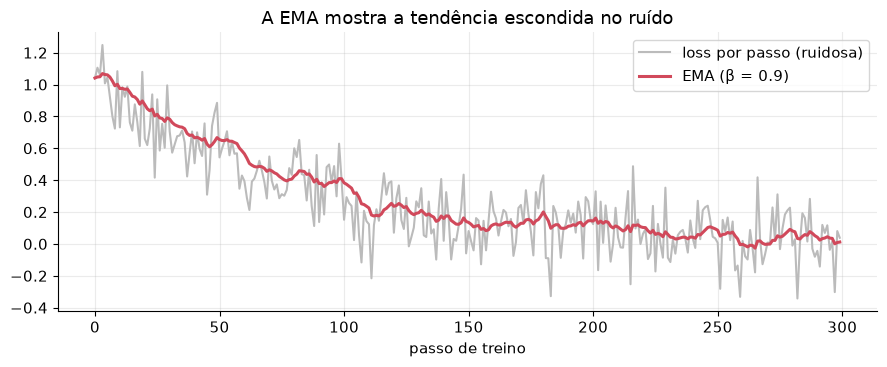

In [34]:
t = np.arange(300)
loss = np.exp(-t / 80) + 0.15 * rng.normal(size=t.size)      # loss ruidosa, decrescente

beta, ema = 0.9, np.empty_like(loss)
ema[0] = loss[0]
for i in range(1, len(loss)):
    ema[i] = beta * ema[i - 1] + (1 - beta) * loss[i]

fig, ax = plt.subplots(figsize=(9, 3.8))
ax.plot(t, loss, color="#bbbbbb", label="loss por passo (ruidosa)")
ax.plot(t, ema, color=COR["media"], lw=2.2, label=f"EMA (β = {beta})")
ax.set_xlabel("passo de treino"); ax.legend(); ax.set_title("A EMA mostra a tendência escondida no ruído")
plt.tight_layout(); plt.show()

### 9.5 · Engenharia e Indústria: latência e MTBF

> 🏭 **No trabalho (backend/telemetria).** Em sistemas, a média de latência é a métrica **mais enganosa** que existe, porque as latências têm cauda longa. Por isso se monitoram os percentis p95 e p99.

In [35]:
latencia_ms = rng.lognormal(mean=4.0, sigma=0.8, size=20_000)    # ms; cauda longa à direita

print(f"média = {latencia_ms.mean():6.1f} ms")
print(f"p50   = {np.percentile(latencia_ms, 50):6.1f} ms")
print(f"p95   = {np.percentile(latencia_ms, 95):6.1f} ms")
print(f"p99   = {np.percentile(latencia_ms, 99):6.1f} ms")
print(f"\n{(latencia_ms > latencia_ms.mean()).mean():.1%} das requisições ficam ACIMA da média")

média =   76.6 ms
p50   =   55.5 ms
p95   =  208.9 ms
p99   =  361.7 ms

34.3% das requisições ficam ACIMA da média


> 🏭 **No trabalho (manutenção e confiabilidade).** O **MTBF** (*Mean Time Between Failures*, tempo médio entre falhas) é uma média, e o erro da média de médias é frequente nele. Considere três máquinas:

In [36]:
maquinas = pd.DataFrame({
    "maquina": ["A", "B", "C"],
    "horas_operadas": [2000, 500, 6000],
    "falhas": [4, 5, 3],
})
maquinas["mtbf"] = maquinas["horas_operadas"] / maquinas["falhas"]
display(maquinas)

mtbf_errado = maquinas["mtbf"].mean()                                   # média das médias
mtbf_certo  = maquinas["horas_operadas"].sum() / maquinas["falhas"].sum()   # horas totais / falhas totais
mtbf_pond   = np.average(maquinas["mtbf"], weights=maquinas["falhas"])      # ponderada pelo nº de falhas

print(f"\nMédia dos MTBFs (errada)             : {mtbf_errado:7.1f} h")
print(f"Horas totais / falhas totais (certa) : {mtbf_certo:7.1f} h")
print(f"MTBFs ponderados pelo nº de falhas   : {mtbf_pond:7.1f} h   <- é a mesma coisa que a certa")
assert np.isclose(mtbf_certo, mtbf_pond)

,maquina,horas_operadas,falhas,mtbf
0,A,2000,4,500.0000
1,B,500,5,100.0000
2,C,6000,3,2000.0000



Média dos MTBFs (errada)             :   866.7 h
Horas totais / falhas totais (certa) :   708.3 h
MTBFs ponderados pelo nº de falhas   :   708.3 h   <- é a mesma coisa que a certa


Mais uma vez a correção é uma média ponderada: cada MTBF deve pesar pelo **número de falhas** que o sustenta. A máquina B, com apenas 500 h de operação, não pode valer o mesmo que a C, com 6.000 h.

---
## 10 · Mini-caso: quem é o melhor produto?

**Contexto.** Um marketplace quer exibir os "melhores produtos" ordenados pela nota média. Mas há produtos com 3 avaliações e outros com 900. Um produto com 3 notas máximas lidera o ranking?

A solução usada por vários sistemas de recomendação é a **média bayesiana**: uma **média ponderada** entre a nota do produto e a nota geral da loja, na qual o produto só "ganha" peso à medida que acumula avaliações:

$$\text{score}_i = \frac{n_i\, \bar{x}_i + m\, C}{n_i + m}$$

Aqui $\bar{x}_i$ é a nota média do produto, $n_i$ é o número de avaliações, $C$ é a nota média de **toda a loja** e $m$ é a "confiança a priori" (quantas avaliações o produto precisa para se afastar de $C$). É uma prévia da inferência bayesiana do Módulo 02.

Vamos simular um catálogo em que **conhecemos a qualidade verdadeira** de cada produto, para poder julgar qual ranking acerta mais:

In [37]:
from scipy.stats import spearmanr

def simular_catalogo(seed, n_produtos=14, m=10, qmin=3.0, qmax=4.6):
    g = np.random.default_rng(seed)
    qualidade = g.uniform(qmin, qmax, n_produtos)                      # verdade (desconhecida na prática)
    n_av = g.permutation(np.array([3, 5, 8, 12, 20, 35, 60, 90, 150, 240, 380, 520, 700, 900]))[:n_produtos]
    # cada avaliação: nota inteira de 1 a 5, centrada na qualidade verdadeira
    medias = np.array([np.clip(np.round(g.normal(q, 1.0, n)), 1, 5).mean() for q, n in zip(qualidade, n_av)])
    C = np.average(medias, weights=n_av)                               # nota média da loja (uma ponderada!)
    score = (n_av * medias + m * C) / (n_av + m)
    return pd.DataFrame({"qualidade_real": qualidade, "n": n_av, "nota_media": medias, "score_bayes": score}), C

catalogo, C = simular_catalogo(seed=7, m=10)
catalogo["rank_simples"] = catalogo["nota_media"].rank(ascending=False).astype(int)
catalogo["rank_bayes"]   = catalogo["score_bayes"].rank(ascending=False).astype(int)

print(f"Nota média da loja (C) = {C:.3f}  |  m = 10 (por enquanto)\n")
catalogo.sort_values("n")[["n", "qualidade_real", "nota_media", "rank_simples", "score_bayes", "rank_bayes"]].round(3)

Nota média da loja (C) = 3.670  |  m = 10 (por enquanto)



,n,qualidade_real,nota_media,rank_simples,score_bayes,rank_bayes
0,3,4.0000,3.6670,9,3.6690,9
12,5,3.4080,3.8000,7,3.7130,7
7,8,4.3140,4.2500,2,3.9280,5
9,12,3.7490,4.1670,5,3.9410,4
3,20,3.3600,3.1500,13,3.3230,13
2,35,4.2410,3.9710,6,3.9040,6
6,60,3.0080,2.9330,14,3.0390,14
8,90,4.2750,4.1890,4,4.1370,3
10,150,3.4850,3.3470,12,3.3670,12
5,240,4.3980,4.2580,1,4.2350,1


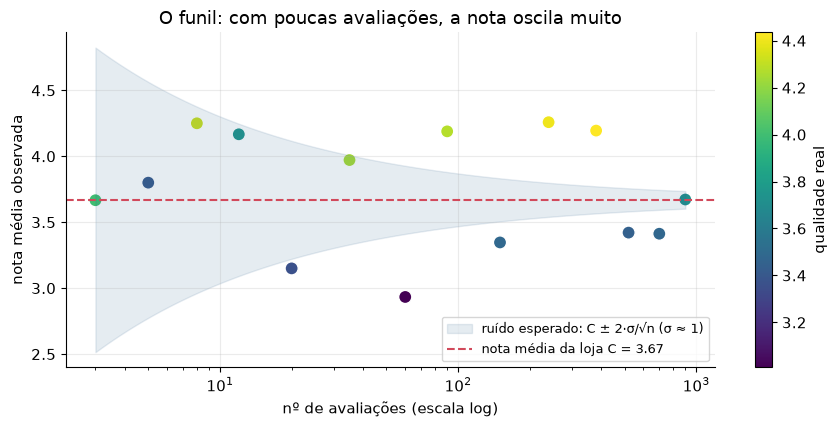

In [38]:
fig, ax = plt.subplots(figsize=(9, 4.4))
sc = ax.scatter(catalogo["n"], catalogo["nota_media"], c=catalogo["qualidade_real"], cmap="viridis", s=90, edgecolor="white")
n_grade = np.logspace(np.log10(3), np.log10(900), 100)
ax.fill_between(n_grade, C - 2 / np.sqrt(n_grade), C + 2 / np.sqrt(n_grade), color=COR["base"], alpha=0.12,
                label="ruído esperado: C ± 2·σ/√n (σ ≈ 1)")
ax.axhline(C, color=COR["media"], ls="--", label=f"nota média da loja C = {C:.2f}")
ax.set_xscale("log"); ax.set_xlabel("nº de avaliações (escala log)"); ax.set_ylabel("nota média observada")
ax.set_title("O funil: com poucas avaliações, a nota oscila muito"); ax.legend(loc="lower right", fontsize=9)
plt.colorbar(sc, label="qualidade real")
plt.tight_layout(); plt.show()

Leia a tabela de cima para baixo: as primeiras linhas são os produtos com **poucas avaliações**. Compare `rank_simples` com `rank_bayes` e veja quem muda de posição.

A faixa sombreada desenha o **funil**: é o ruído que esperaríamos na nota média se todos os produtos tivessem a mesma qualidade, e ela se estreita proporcionalmente a $1/\sqrt{n}$. Com poucas avaliações a nota oscila muito, e com muitas ela se estabiliza. Esse é o **erro padrão** da média, tema que voltará em força no Teorema Central do Limite.

Mas um único catálogo pode ser sorte, e o valor $m = 10$ foi um palpite. Vamos testar vários $m$ em **300 catálogos simulados** (os mesmos para todos os $m$) e medir quão bem cada ranking reproduz a qualidade real (correlação de Spearman: quanto mais perto de 1, melhor). Repare que **$m = 0$ é a nota média simples**, sem ancoragem alguma:

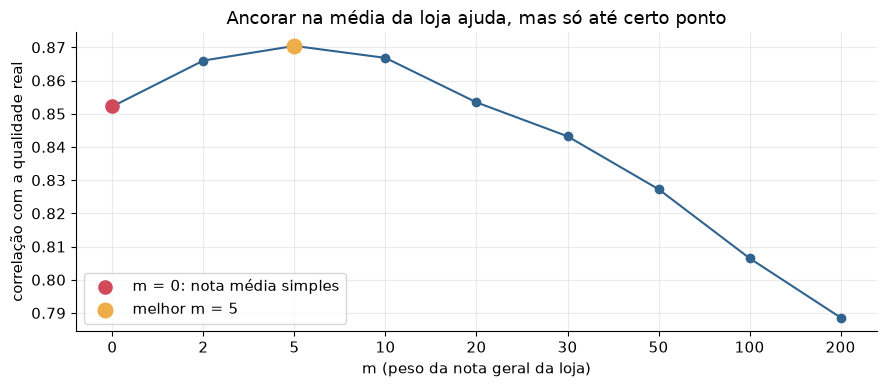

,correlacao_media
0,0.8522
2,0.8660
5,0.8704
10,0.8668
20,0.8534
30,0.8432
50,0.8273
100,0.8065
200,0.7886


In [39]:
def avaliar(m, n_simulacoes=300, **kw):
    """Correlação média (Spearman) entre a qualidade real e o ranking por score bayesiano."""
    rhos = []
    for s in range(n_simulacoes):
        cat, _ = simular_catalogo(seed=s, m=m, **kw)
        rhos.append(spearmanr(cat["qualidade_real"], cat["score_bayes"]).statistic)
    return float(np.mean(rhos))

grade_m = [0, 2, 5, 10, 20, 30, 50, 100, 200]
curva = pd.Series({m: avaliar(m) for m in grade_m}, name="correlacao_media")
melhor_m = curva.idxmax()

xs = np.arange(len(curva))
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(xs, curva.values, marker="o", color=COR["base"])
ax.scatter([0], [curva.iloc[0]], color=COR["media"], zorder=5, s=90, label="m = 0: nota média simples")
pos_melhor = list(curva.index).index(melhor_m)
ax.scatter([pos_melhor], [curva[melhor_m]], color=COR["ponderada"], zorder=5, s=110, label=f"melhor m = {melhor_m}")
ax.set_xticks(xs); ax.set_xticklabels(curva.index)
ax.set_xlabel("m (peso da nota geral da loja)")
ax.set_ylabel("correlação com a qualidade real"); ax.legend(loc="lower left")
ax.set_title("Ancorar na média da loja ajuda, mas só até certo ponto")
plt.tight_layout(); plt.show()
curva.round(4).to_frame()

A curva conta uma história em três partes:

- **$m = 0$ (nota simples):** produtos com poucas avaliações têm notas ruidosas e embaralham o ranking.
- **$m$ moderado:** ancorar esses produtos na nota da loja **melhora** o ranking. Você acabou de implementar *shrinkage*, a ideia que reaparece em modelos hierárquicos, regularização e inferência bayesiana.
- **$m$ muito grande:** todo produto "colapsa" para a nota da loja e **jogamos fora evidência real**. O ranking piora de novo.

Escolher $m$ é um equilíbrio entre **confiar nos dados** (ruidosos) e **confiar na âncora** (enviesada), o mesmo dilema que você vai encontrar como *viés versus variância* em Machine Learning. O mecanismo, porém, é o da seção 1: **ponderar pelo tamanho da evidência**.

---
# ATO VI · FIXAR
## 11 · Entrevista e exercícios

### 🎯 Perguntas de entrevista

Tente responder em voz alta antes de abrir cada resposta.

<details><summary><b>1. Qual medida minimiza o erro quadrático? E o erro absoluto?</b></summary>

A média minimiza $\sum (x_i - c)^2$ e a mediana minimiza $\sum |x_i - c|$. Por isso a média é a base do MSE e dos modelos de referência (*baselines*), e a mediana é a base da regressão robusta (perda MAE).
</details>

<details><summary><b>2. Por que a média das médias pode estar errada?</b></summary>

Porque a média geral é a **média ponderada** das médias dos grupos, com pesos iguais aos tamanhos $n_g$. A média simples das médias só coincide com ela se todos os grupos tiverem o mesmo tamanho.
</details>

<details><summary><b>3. O que faz <code>average="weighted"</code> no F1?</b></summary>

Calcula uma média ponderada dos F1 de cada classe, com peso igual ao suporte (nº de exemplos reais) da classe. A classe majoritária domina, e por isso o resultado pode esconder um desempenho ruim na classe rara. O `macro` usa média simples e expõe esse problema.
</details>

<details><summary><b>4. A média é robusta a outliers? Como medir isso?</b></summary>

Não. O seu ponto de ruptura (*breakdown point*) é 0%: um único valor arbitrariamente grande leva a média a qualquer lugar. A mediana tem ponto de ruptura de 50%. Alternativas: mediana, média truncada, winsorização.
</details>

<details><summary><b>5. Quando usar a média harmônica?</b></summary>

Em razões e taxas com numerador fixo, como velocidade média em trechos iguais, preço por unidade com gasto igual, e o F1-score (média harmônica de precisão e revocação).
</details>

### ✏️ Exercícios

Resolva **antes** de olhar o gabarito no apêndice ao final.

**Básico**

- **B1.** Calcule, sem bibliotecas, a média simples e a ponderada de `x = [12, 15, 9, 20, 14]` com pesos `w = [1, 2, 1, 3, 3]`.
- **B2.** Em `vendas` (abaixo), calcule o **preço médio efetivo** de cada loja, ponderando o preço pela quantidade vendida.
- **B3.** Verifique numericamente que a soma dos desvios de `df["compras_ano"]` em torno da média é zero.

**Intermediário**

- **I1.** Escreva `media_ponderada_segura(x, w)`, que **ignora** os pares em que `x` ou `w` seja `NaN` e valida os pesos. Teste com `x = [4, nan, 5]` e `w = [1, 2, 3]`.
- **I2.** Calcule o MTBF correto da planta com `fabrica` (abaixo) e compare com a média dos MTBFs.
- **I3.** Com o dataset, calcule a **nota ponderada por faixa etária** (18–30, 31–45, 46–60, 61–69), reaproveitando `media_ponderada_por_grupo`.

**Desafio**

- **D1.** Refaça a curva da seção 10 com um catálogo em que as qualidades reais são **muito parecidas** (`qmin=3.6, qmax=4.0`). O melhor $m$ muda? Por quê?
- **D2.** Demonstre analiticamente que $\sum (x_i - c)^2$ é minimizado em $c = \bar{x}$.

In [40]:
# Dados dos exercícios B2 e I2
vendas = pd.DataFrame({
    "loja":  ["A", "A", "B", "B", "B"],
    "preco": [10, 12, 8, 9, 11],
    "qtd":   [100, 50, 300, 200, 100],
})
fabrica = pd.DataFrame({
    "linha":   ["L1", "L2", "L3"],
    "horas":   [3000, 800, 9000],
    "falhas":  [6, 8, 5],
})

# ✏️ Resolva aqui (B1, B2, B3, I1, I2, I3, D1)

---
## 12 · Resumo e ponte

### 🧾 Cheat-sheet

| | Média aritmética | Média ponderada |
|---|---|---|
| **Fórmula** | $\bar{x} = \frac{1}{n}\sum x_i$ | $\bar{x}_w = \frac{\sum w_i x_i}{\sum w_i}$ |
| **NumPy** | `np.mean(x)` | `np.average(x, weights=w)` |
| **Pandas** | `s.mean()` | `(s * w).sum() / w.sum()` |
| **Com NaN** | `np.nanmean`, `skipna=True` | filtrar valor **e** peso juntos |
| **Use quando** | observações com mesma importância | observações de tamanhos/importâncias diferentes |
| **Cuidado** | outliers e distribuições assimétricas | pesos inválidos e média de médias |

### 🔑 As 7 ideias para levar

1. A média é o **ponto de equilíbrio** dos dados.
2. Ela **minimiza o erro quadrático**, base do MSE e dos *baselines*.
3. A média simples é a ponderada com **pesos iguais**.
4. A média geral é a **ponderada das médias dos grupos** (pelos $n_g$).
5. Ela **não resiste a outliers** e **esconde a forma** da distribuição.
6. Para razões, use a **harmônica**; para fatores, a **geométrica**.
7. **Ponderar pelo tamanho da evidência** (média bayesiana) é a ideia por trás do *shrinkage*.

### 📚 Referências

- BUSSAB, W. O.; MORETTIN, P. A. *Estatística Básica*. Saraiva.
- MORETTIN, P. A.; SINGER, J. M. *Estatística e Ciência de Dados*. LTC.
- Documentação: [`numpy.average`](https://numpy.org/doc/stable/reference/generated/numpy.average.html) · [`pandas.DataFrame.mean`](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.mean.html) · [`sklearn.metrics.f1_score`](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.f1_score.html)

---
# 📎 APÊNDICE · Gabarito comentado

In [41]:
# ── B1 ─────────────────────────────────────────────────────────────
x1, w1 = [12, 15, 9, 20, 14], [1, 2, 1, 3, 3]
print("B1  simples  =", media(x1), "| ponderada =", media_ponderada(x1, w1))      # 14.0 e 15.3
assert np.isclose(media_ponderada(x1, w1), (12*1 + 15*2 + 9*1 + 20*3 + 14*3) / 10)

# ── B2 ─────────────────────────────────────────────────────────────
b2 = vendas.assign(receita=vendas["preco"] * vendas["qtd"]).groupby("loja")[["receita", "qtd"]].sum()
b2["preco_medio_efetivo"] = b2["receita"] / b2["qtd"]
print("\nB2"); display(b2)

# ── B3 ─────────────────────────────────────────────────────────────
c = df["compras_ano"]
print("\nB3  soma dos desvios de compras_ano =", (c - c.mean()).sum())
assert np.isclose((c - c.mean()).sum(), 0)

B1  simples  = 14.0 | ponderada = 15.3

B2


,receita,qtd,preco_medio_efetivo
loja,,,
A,1600,150,10.6667
B,5300,600,8.8333



B3  soma dos desvios de compras_ano = -2.7533531010703882e-14


In [42]:
# ── I1 ─────────────────────────────────────────────────────────────
def media_ponderada_segura(x, w):
    x, w = np.asarray(x, float), np.asarray(w, float)
    if x.shape != w.shape:
        raise ValueError("x e w precisam ter o mesmo tamanho")
    ok = ~(np.isnan(x) | np.isnan(w))          # o filtro vale para o PAR (valor, peso)
    x, w = x[ok], w[ok]
    if (w < 0).any():
        raise ValueError("pesos negativos")
    if w.sum() == 0:
        raise ValueError("soma dos pesos zero depois de remover NaN")
    return float((x * w).sum() / w.sum())

r = media_ponderada_segura([4, np.nan, 5], [1, 2, 3])
print("I1  resultado =", r, "(esperado 4.75 = (4*1 + 5*3) / 4)")
assert np.isclose(r, 4.75)

# ── I2 ─────────────────────────────────────────────────────────────
fabrica["mtbf"] = fabrica["horas"] / fabrica["falhas"]
print("\nI2  média dos MTBFs         =", round(fabrica["mtbf"].mean(), 1), "h  (errada)")
print("    horas totais/falhas totais =", round(fabrica["horas"].sum() / fabrica["falhas"].sum(), 1), "h  (certa)")

# ── I3 ─────────────────────────────────────────────────────────────
faixas = df.assign(faixa=pd.cut(df["idade"], bins=[17, 30, 45, 60, 69], labels=["18-30", "31-45", "46-60", "61-69"]))
print("\nI3"); display(media_ponderada_por_grupo(faixas, "nota_satisfacao", "peso_avaliacoes", "faixa"))

I1  resultado = 4.75 (esperado 4.75 = (4*1 + 5*3) / 4)

I2  média dos MTBFs         = 800.0 h  (errada)
    horas totais/falhas totais = 673.7 h  (certa)

I3


,n,soma_pesos,simples,ponderada,diferenca
faixa,,,,,
18-30,45,1122,2.9956,2.9676,-0.0279
31-45,56,1344,3.0179,2.9704,-0.0475
46-60,51,1182,2.7882,2.7146,-0.0736
61-69,32,852,3.0156,3.0202,0.0046


In [43]:
# ── D1 ─────────────────────────────────────────────────────────────
curva_estreita = pd.Series({m: avaliar(m, n_simulacoes=200, qmin=3.6, qmax=4.0) for m in grade_m})
print(f"Qualidades entre 3,0 e 4,6 -> melhor m = {melhor_m}")
print(f"Qualidades entre 3,6 e 4,0 -> melhor m = {curva_estreita.idxmax()}\n")
pd.DataFrame({"amplo (3,0 a 4,6)": curva, "estreito (3,6 a 4,0)": curva_estreita}).round(4)

Qualidades entre 3,0 e 4,6 -> melhor m = 5
Qualidades entre 3,6 e 4,0 -> melhor m = 100



,"amplo (3,0 a 4,6)","estreito (3,6 a 4,0)"
0,0.8522,0.4920
2,0.8660,0.5058
5,0.8704,0.5275
10,0.8668,0.5485
20,0.8534,0.5775
30,0.8432,0.5900
50,0.8273,0.6033
100,0.8065,0.6103
200,0.7886,0.6079


**D1 · Leitura.** Quando as qualidades reais são parecidas, quase toda a diferença **observada** entre os produtos é ruído de amostragem. Ancorar mais forte passa a compensar, e o melhor $m$ salta para um valor bem maior (100 nesta simulação, contra 5 no catálogo amplo). Regra de bolso: **quanto menor a variação verdadeira entre os grupos, em relação ao ruído, mais *shrinkage* vale a pena.** É exatamente o raciocínio por trás da regularização em Machine Learning.

**D2 · Demonstração.** Seja $f(c) = \sum_{i=1}^{n} (x_i - c)^2$. Derivando em relação a $c$:

$$f'(c) = -2\sum_{i=1}^{n}(x_i - c) = 0 \;\Longrightarrow\; \sum x_i = n\,c \;\Longrightarrow\; c = \bar{x}.$$

A segunda derivada é $f''(c) = 2n > 0$, logo $c = \bar{x}$ é um **mínimo** (e único, pois $f$ é uma parábola). $\blacksquare$

Observação: $f(\bar{x}) = \sum (x_i - \bar{x})^2 = (n-1)s^2$, o que liga este resultado à **variância**, tema da aula sobre dispersão.